# Cross-Sectional Stock Return Prediction

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf

In [2]:
#Chosen stocks
tickers = [
    # Technology
    "AAPL", "MSFT", "NVDA", "AVGO", "ORCL",
    "AMD", "CSCO", "IBM", "QCOM", "TXN",

    # Communication services
    "GOOGL", "META", "NFLX", "DIS", "TMUS",
    "VZ", "T", "CMCSA",

    # Consumer discretionary
    "AMZN", "TSLA", "HD", "MCD", "NKE",
    "LOW", "TJX", "BKNG",

    # Consumer staples
    "WMT", "COST", "PG", "KO", "PEP",

    # Financials
    "JPM", "BAC", "GS", "MS", "WFC",
    "C", "AXP",

    # Healthcare
    "LLY", "JNJ", "ABBV", "MRK", "UNH",

    # Energy
    "XOM", "CVX",

    # Industrials
    "CAT", "GE", "HON", "UPS", "DE"
]

print("Number of unique stocks:", len(set(tickers)))

Number of unique stocks: 50


In [3]:
#Download data
start_date = '2010-01-01'
end_date = '2026-01-01'

prices = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)["Close"]
prices = prices.sort_index()
prices.head()

[*********************100%***********************]  50 of 50 completed


Ticker,AAPL,ABBV,AMD,AMZN,AVGO,AXP,BAC,BKNG,C,CAT,...,TJX,TMUS,TSLA,TXN,UNH,UPS,VZ,WFC,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2010-01-04,6.400961,NaN,9.70,6.6950,1.321281,32.192970,11.977126,8.750930,24.852760,38.959282,...,7.227365,12.557343,NaN,16.852442,24.120546,32.435440,12.893181,17.734049,12.878363,37.136818
2010-01-05,6.412027,NaN,9.71,6.7345,1.331089,32.122181,12.366438,8.852521,25.803007,39.425053,...,7.421887,12.588853,NaN,16.755247,24.082302,32.491169,12.916421,18.220896,12.750122,37.281815
2010-01-06,6.310036,NaN,9.57,6.6125,1.341597,32.641422,12.511478,8.560248,26.607071,39.544846,...,7.451968,11.738042,NaN,16.632154,24.319462,32.251438,12.545021,18.246861,12.721624,37.604050
2010-01-07,6.298369,NaN,9.47,6.5000,1.333191,33.170822,12.923692,8.444982,26.680166,39.704533,...,7.832988,11.848331,NaN,16.683977,25.252760,32.006142,12.470354,18.908968,12.728744,37.485897
2010-01-08,6.340244,NaN,9.43,6.6760,1.342999,33.147118,12.809182,8.448110,26.241596,40.150360,...,7.730716,11.186593,NaN,17.066254,25.015608,33.544842,12.478209,18.733707,12.664627,37.335514


In [4]:
print(prices.shape)
print(prices.notna().sum().sort_values())

(4024, 50)
Ticker
ABBV     3270
META     3425
TSLA     3902
AAPL     4024
MCD      4024
MRK      4024
MS       4024
MSFT     4024
NFLX     4024
NKE      4024
NVDA     4024
ORCL     4024
PEP      4024
PG       4024
QCOM     4024
T        4024
TJX      4024
TMUS     4024
TXN      4024
UNH      4024
UPS      4024
VZ       4024
WFC      4024
LOW      4024
LLY      4024
KO       4024
JPM      4024
AMD      4024
AMZN     4024
AVGO     4024
AXP      4024
BAC      4024
BKNG     4024
C        4024
CAT      4024
CMCSA    4024
COST     4024
CSCO     4024
CVX      4024
DE       4024
DIS      4024
GE       4024
GOOGL    4024
GS       4024
HD       4024
HON      4024
IBM      4024
JNJ      4024
WMT      4024
XOM      4024
dtype: int64


In [5]:
market_prices = yf.download(
    "^GSPC",
    start=start_date,
    end=end_date,
    auto_adjust=True
)["Close"]

market_prices = market_prices.sort_index()

[*********************100%***********************]  1 of 1 completed


In [ ]:
prices_monthly = prices.resample("ME").last() #Month's end closing prices
returns_monthly = prices_monthly.pct_change() #Calculate returns

returns_monthly.head()

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,META,MSFT,NVDA,PG,XOM
Date,,,,,,,,,,
2015-01-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-02-28,0.100777,0.072293,0.046656,0.030832,0.126885,0.040311,0.093121,0.153383,0.009966,0.020435
2015-03-31,-0.031372,-0.021202,-0.014094,-0.018632,-0.011423,0.041155,-0.072749,-0.051225,-0.037473,-0.039982
2015-04-30,0.005786,0.133513,-0.010691,-0.013917,0.051180,-0.041961,0.196262,0.060679,-0.021850,0.027883
2015-05-31,0.045339,0.017663,-0.006287,0.016837,0.039835,0.005332,-0.030334,0.001461,-0.014086,-0.016771


In [5]:
#target variable
future_returns = returns_monthly.shift(-1)
future_returns.head()

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,META,MSFT,NVDA,PG,XOM
Date,,,,,,,,,,
2015-01-31,0.100777,0.072293,0.046656,0.030832,0.126885,0.040311,0.093121,0.153383,0.009966,0.020435
2015-02-28,-0.031372,-0.021202,-0.014094,-0.018632,-0.011423,0.041155,-0.072749,-0.051225,-0.037473,-0.039982
2015-03-31,0.005786,0.133513,-0.010691,-0.013917,0.051180,-0.041961,0.196262,0.060679,-0.021850,0.027883
2015-04-30,0.045339,0.017663,-0.006287,0.016837,0.039835,0.005332,-0.030334,0.001461,-0.014086,-0.016771
2015-05-31,-0.037227,0.011323,-0.009682,-0.026763,0.030101,0.083091,-0.057832,-0.091279,-0.001914,-0.023474


## Feature Engineering

In [6]:
# features_df = future_returns.reset_index().melt(
#     id_vars="Date",
#     var_name="Ticker",
#     value_name="Future Returns"
# )

# features_df.head()


### Momentum

The momentum at time $t$ is given by $$ \frac{P_{t-1}}{P_{t-12}} - 1 $$

measuring how much the stock has increased or decreaed over the past year

In [7]:
momentum = prices_monthly.shift(1) / prices_monthly.shift(12) - 1

In [8]:
momentum_df = momentum.reset_index().melt(
    id_vars="Date",
    var_name="Ticker",
    value_name="Momentum"
)

features_df = momentum_df.copy()
features_df.tail()

,Date,Ticker,Momentum
1315,2025-08-31,XOM,-0.028234
1316,2025-09-30,XOM,0.010258
1317,2025-10-31,XOM,0.000400
1318,2025-11-30,XOM,-0.003652
1319,2025-12-31,XOM,0.117174


### Volatility

In [9]:
volatility = prices_monthly.rolling(12).std()

In [10]:
volatility_df = volatility.reset_index().melt(
    id_vars="Date",
    var_name="Ticker",
    value_name="Volatility"
)
features_df['Volatility'] = volatility_df['Volatility']
features_df.tail()

,Date,Ticker,Momentum,Volatility
1315,2025-08-31,XOM,-0.028234,4.983386
1316,2025-09-30,XOM,0.010258,4.959672
1317,2025-10-31,XOM,0.000400,5.077396
1318,2025-11-30,XOM,-0.003652,5.302775
1319,2025-12-31,XOM,0.117174,5.991958


### Beta

In [11]:
#Download market data
market = yf.download(
    "^GSPC",
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=True
)

market_prices = market["Close"].resample("ME").last()
market_returns = market_prices.squeeze().pct_change()

[*********************100%***********************]  1 of 1 completed


In [12]:
returns_monthly = returns_monthly.astype(float)
market_returns = market_returns.astype(float)


In [13]:
#Calculate betas
betas = {}
for ticker in tickers:
    betas[ticker] = returns_monthly[ticker].rolling(12).cov(market_returns) / market_returns.rolling(12).var()

betas

{'AAPL': Date
 2015-01-31         NaN
 2015-02-28         NaN
 2015-03-31         NaN
 2015-04-30         NaN
 2015-05-31         NaN
                 ...   
 2025-08-31    0.368903
 2025-09-30    0.493241
 2025-10-31    0.463809
 2025-11-30    0.389568
 2025-12-31    0.619201
 Freq: ME, Length: 132, dtype: float64,
 'MSFT': Date
 2015-01-31         NaN
 2015-02-28         NaN
 2015-03-31         NaN
 2015-04-30         NaN
 2015-05-31         NaN
                 ...   
 2025-08-31    1.342136
 2025-09-30    1.298323
 2025-10-31    1.202574
 2025-11-30    1.352794
 2025-12-31    1.473588
 Freq: ME, Length: 132, dtype: float64,
 'GOOGL': Date
 2015-01-31         NaN
 2015-02-28         NaN
 2015-03-31         NaN
 2015-04-30         NaN
 2015-05-31         NaN
                 ...   
 2025-08-31    0.879257
 2025-09-30    1.034017
 2025-10-31    1.122436
 2025-11-30    1.435124
 2025-12-31    1.908740
 Freq: ME, Length: 132, dtype: float64,
 'AMZN': Date
 2015-01-31         NaN
 2015-0

In [14]:
betas_predf = pd.DataFrame(betas)
betas_df = betas_predf.reset_index().melt(
    id_vars="Date",
    var_name="Ticker",
    value_name="Beta"
)

betas_df

,Date,Ticker,Beta
0,2015-01-31,AAPL,NaN
1,2015-02-28,AAPL,NaN
2,2015-03-31,AAPL,NaN
3,2015-04-30,AAPL,NaN
4,2015-05-31,AAPL,NaN
...,...,...,...
1315,2025-08-31,PG,0.552708
1316,2025-09-30,PG,0.501825
1317,2025-10-31,PG,0.454633
1318,2025-11-30,PG,0.190867


In [15]:
features_df['Beta'] = betas_df['Beta']
features_df.tail()

,Date,Ticker,Momentum,Volatility,Beta
1315,2025-08-31,XOM,-0.028234,4.983386,0.552708
1316,2025-09-30,XOM,0.010258,4.959672,0.501825
1317,2025-10-31,XOM,0.000400,5.077396,0.454633
1318,2025-11-30,XOM,-0.003652,5.302775,0.190867
1319,2025-12-31,XOM,0.117174,5.991958,0.057403


### Current Size \& Value

Note: need to be adjusted into historical data for backtesting, but temporarily uses current data

In [16]:
market_caps = {}
pe_ratios = {}

for ticker in tickers:
    info = yf.Ticker(ticker).info
    market_caps[ticker] = info.get('marketCap')
    pe_ratios[ticker] = info.get('trailingPE')

In [17]:
market_caps

{'AAPL': 5017916932096,
 'MSFT': 3943039238144,
 'GOOGL': 3973383716864,
 'AMZN': 2746195378176,
 'META': 1594209206272,
 'NVDA': 5200780722176,
 'JPM': 901045092352,
 'XOM': 748450217984,
 'JNJ': 652477399040,
 'PG': 366812332032}

In [18]:
#Use log market cap instead for feature
log_market_caps = {
    ticker : float(np.log(cap))
    for ticker, cap in market_caps.items()
    if cap is not None
}

log_market_caps

{'AAPL': 29.244036009749312,
 'MSFT': 29.002972922117156,
 'GOOGL': 29.01063916923604,
 'AMZN': 28.64123757084379,
 'META': 28.097398933777406,
 'NVDA': 29.279829869126218,
 'JPM': 27.526821140307987,
 'XOM': 27.34127052955486,
 'JNJ': 27.204042338056777,
 'PG': 26.628116197352437}

In [19]:
#P/E ratios to Earnings yield

earnings_yield = {
    ticker : 1 / pe
    for ticker, pe in pe_ratios.items()
    if pe is not None and pe > 0
}

earnings_yield

{'AAPL': 0.025361372934880465,
 'MSFT': 0.03380350630249473,
 'GOOGL': 0.058943024258119515,
 'AMZN': 0.048821683779806,
 'META': 0.047853843642255575,
 'NVDA': 0.036725786000681264,
 'JPM': 0.07026230746195543,
 'XOM': 0.04318206942294937,
 'JNJ': 0.024313754609492776,
 'PG': 0.04195627510007935}

In [20]:
curr_df = pd.DataFrame({
    "Ticker" : list(log_market_caps.keys()),
    "Size" : log_market_caps.values(),
    "Value" : earnings_yield.values()
})

curr_df.head()

,Ticker,Size,Value
0,AAPL,29.244036,0.025361
1,MSFT,29.002973,0.033804
2,GOOGL,29.010639,0.058943
3,AMZN,28.641238,0.048822
4,META,28.097399,0.047854


In [21]:
features_df = features_df.merge(
    curr_df,
    on="Ticker",
    how="left"
)

features_df.tail()

,Date,Ticker,Momentum,Volatility,Beta,Size,Value
1315,2025-08-31,XOM,-0.028234,4.983386,0.552708,27.341271,0.043182
1316,2025-09-30,XOM,0.010258,4.959672,0.501825,27.341271,0.043182
1317,2025-10-31,XOM,0.000400,5.077396,0.454633,27.341271,0.043182
1318,2025-11-30,XOM,-0.003652,5.302775,0.190867,27.341271,0.043182
1319,2025-12-31,XOM,0.117174,5.991958,0.057403,27.341271,0.043182


In [22]:
target_df = future_returns.reset_index().melt(
    id_vars="Date",
    var_name="Ticker",
    value_name="Future Returns"
)

features_df['Future Returns'] = target_df['Future Returns']
features_df.tail()

,Date,Ticker,Momentum,Volatility,Beta,Size,Value,Future Returns
1315,2025-08-31,XOM,-0.028234,4.983386,0.552708,27.341271,0.043182,-0.013475
1316,2025-09-30,XOM,0.010258,4.959672,0.501825,27.341271,0.043182,0.014279
1317,2025-10-31,XOM,0.000400,5.077396,0.454633,27.341271,0.043182,0.022507
1318,2025-11-30,XOM,-0.003652,5.302775,0.190867,27.341271,0.043182,0.038130
1319,2025-12-31,XOM,0.117174,5.991958,0.057403,27.341271,0.043182,NaN


## Data Cleaning

remove NaN values

In [23]:
data = features_df.dropna(subset=['Momentum', 'Volatility', 'Beta', 'Size', 'Value', 'Future Returns']).copy()

print(data.shape)
print(data.head())

(1190, 8)
         Date Ticker  Momentum  Volatility      Beta       Size     Value  \
12 2016-01-31   AAPL -0.086263    2.129121  1.279012  29.244036  0.025361   
13 2016-02-29   AAPL -0.232373    2.380289  1.116993  29.244036  0.025361   
14 2016-03-31   AAPL -0.208532    2.333381  1.340059  29.244036  0.025361   
15 2016-04-30   AAPL -0.112981    2.539117  1.320438  29.244036  0.025361   
16 2016-05-31   AAPL -0.270183    2.278701  1.347973  29.244036  0.025361   

    Future Returns  
12       -0.001287  
13        0.127211  
14       -0.139921  
15        0.071773  
16       -0.042659  


split data

In [24]:
data['Date'] = pd.to_datetime(data['Date'])

train = data[data['Date'] < '2024-01-01'].copy()
test = data[data['Date'] >= '2024-01-01'].copy()

print(len(train) , len(test))

960 230


In [25]:
features = ['Momentum', 'Volatility', 'Beta', 'Size', 'Value']

X_train = train[features]
y_train = train['Future Returns']

X_test = test[features]
y_test = test['Future Returns']

## Baseline Linear Regression Model

In [26]:
from sklearn.linear_model import LinearRegression

lm = LinearRegression()
lm.fit(X_train, y_train)

preds_lm = lm.predict(X_test)
test['Predicted Returns'] = preds_lm

In [27]:
from sklearn.metrics import mean_squared_error, r2_score

rmse_lm = np.sqrt(mean_squared_error(y_test, preds_lm))
r2_lm = r2_score(y_test, preds_lm)

print('RMSE:', rmse_lm)
print('R2:', r2_lm)

RMSE: 0.07164562694347065
R2: 0.011384356118040562


In [28]:
mic_lm = test.groupby('Date').apply(
    lambda x: x['Predicted Returns'].corr(x['Future Returns']),
    include_groups=False
)

print("LM Mean Monthly IC:", mic_lm.mean())
print("LM Monthly IC St. Dev.:", mic_lm.std())

LM Mean Monthly IC: 0.14752834704993179
LM Monthly IC St. Dev.: 0.39037180806149263


## Ridge Regression

In [29]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

val_years = [2020, 2021, 2022, 2023]
alphas = [0.01, 0.1, 1.0, 10, 100, 1000, 10000, 100000]

results = []

for alpha in alphas:
    rmses = []
    for year in val_years:
        train_fold = data[data['Date'].dt.year < year]
        val_fold = data[data['Date'].dt.year == year]

        ridge = make_pipeline(
            StandardScaler(),
            Ridge(alpha=alpha)
        )

        ridge.fit(train_fold[features], train_fold['Future Returns'])
        preds_ridge = ridge.predict(val_fold[features])

        rmse = np.sqrt(mean_squared_error(val_fold['Future Returns'], preds_ridge))
        rmses.append(rmse)

    results.append({
        "alpha": alpha,
        "mean_val_rmse": np.mean(rmses)
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values("mean_val_rmse"))
    

       alpha  mean_val_rmse
5    1000.00       0.094721
6   10000.00       0.094865
7  100000.00       0.094922
4     100.00       0.094947
3      10.00       0.095070
2       1.00       0.095086
1       0.10       0.095087
0       0.01       0.095087


In [30]:
ridge = make_pipeline(
        StandardScaler(),
        Ridge(alpha=1000)
    )

ridge.fit(X_train, y_train)
preds_ridge = ridge.predict(X_test)
test['Predicted Returns_Ridge'] = preds_ridge

In [31]:
rmse_ridge = np.sqrt(mean_squared_error(y_test, preds_ridge))
r2_ridge = r2_score(y_test, preds_ridge)

print('RMSE:', rmse_ridge)
print('R2:', r2_ridge)

RMSE: 0.07157581798807307
R2: 0.013309961512992685


There is a slightly lower RMSE (-0.0002) and slightly higher R2 (+0.0034) in the Ridge regression model than the baseline linear model.

In [32]:
mic_ridge = test.groupby('Date').apply(
    lambda x: x['Predicted Returns_Ridge'].corr(x['Future Returns']),
    include_groups=False
)

print("Ridge Mean Monthly IC:", mic_ridge.mean())
print("Ridge Monthly IC St. Dev.:", mic_ridge.std())

Ridge Mean Monthly IC: 0.149308899950443
Ridge Monthly IC St. Dev.: 0.39415231016832597


## XGBoost Regressor

In [33]:
from xgboost import XGBRegressor
from itertools import product

val_years = [2020, 2021, 2022, 2023]
trees = [100, 200, 300, 400, 500]
depths =[2, 3, 4]
lrs = [0.005, 0.01, 0.05, 0.1]

params = list(product(
    trees,
    depths,
    lrs
))

results_xgb = []

for num_trees, depth, lr in params:
    rmses = []
    for year in val_years:
        train_fold = data[data['Date'].dt.year < year]
        val_fold = data[data['Date'].dt.year == year]

        if train_fold.empty or val_fold.empty:
            continue

        xgb = XGBRegressor(
            n_estimators=num_trees,
            max_depth=depth,
            learning_rate=lr,
            objective='reg:squarederror',
            random_state=42
        )

        xgb.fit(train_fold[features], train_fold['Future Returns'])
        preds_xgb = xgb.predict(val_fold[features])

        rmse = np.sqrt(mean_squared_error(val_fold['Future Returns'], preds_xgb))
        rmses.append(rmse)

    results_xgb.append({
        "num_trees": num_trees,
        "depth": depth,
        "learnng_rate": lr,
        "mean_val_rmse": np.mean(rmses)
    })

results_df = pd.DataFrame(results_xgb)
print(results_df.sort_values("mean_val_rmse").head(10))

    num_trees  depth  learnng_rate  mean_val_rmse
0         100      2         0.005       0.095028
12        200      2         0.005       0.095091
1         100      2         0.010       0.095091
24        300      2         0.005       0.095173
4         100      3         0.005       0.095234
36        400      2         0.005       0.095273
13        200      2         0.010       0.095276
5         100      3         0.010       0.095384
16        200      3         0.005       0.095389
48        500      2         0.005       0.095479


In [34]:
xgb = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.005,
    objective='reg:squarederror',
    random_state=42
    )

xgb.fit(X_train, y_train)
preds_xgb = xgb.predict(X_test)
test['Predicted Returns_XGB'] = preds_xgb

In [35]:
rmse_xgb = np.sqrt(mean_squared_error(y_test, preds_xgb))
r2_xgb = r2_score(y_test, preds_xgb)

print('RMSE:', rmse_xgb)
print('R2:', r2_xgb)

RMSE: 0.0719585854374016
R2: 0.002728659495986663


In [36]:
mic_xgb = test.groupby('Date').apply(
    lambda x: x['Predicted Returns_XGB'].corr(x['Future Returns']),
    include_groups=False
)

print("XGB Mean Monthly IC:", mic_xgb.mean())
print("XGB Monthly IC St. Dev.:", mic_xgb.std())

XGB Mean Monthly IC: 0.12436950869360519
XGB Monthly IC St. Dev.: 0.39101590816335713


## Monthly IC Comparison

In [37]:
mics = pd.DataFrame({
    "Linear": mic_lm,
    "Ridge": mic_ridge,
    "XGB": mic_xgb
})

mics

,Linear,Ridge,XGB
Date,,,
2024-01-31,0.219319,0.341664,0.690156
2024-02-29,0.332663,0.312755,0.299164
2024-03-31,0.392694,0.268773,-0.597785
2024-04-30,0.629716,0.722301,0.558633
2024-05-31,0.488796,0.558455,0.526078
2024-06-30,-0.039109,-0.107577,-0.298537
2024-07-31,-0.693048,-0.647007,-0.268692
2024-08-31,-0.205175,-0.140403,0.014407
2024-09-30,0.294981,0.342669,0.703705


In [38]:
print("Mean Linear IC:", mics["Linear"].mean())
print("Mean Ridge IC:", mics["Ridge"].mean())
print("Mean XGBoost IC:", mics["XGB"].mean())

Mean Linear IC: 0.14752834704993179
Mean Ridge IC: 0.149308899950443
Mean XGBoost IC: 0.12436950869360519


In [39]:
#Linear vs. Ridge

diff = mics["Linear"] - mics ["Ridge"]

print("Ridge wins:", (diff < 0).sum())
print("Linear wins:", (diff > 0).sum())

Ridge wins: 9
Linear wins: 14


In [40]:
import matplotlib.pyplot as plt

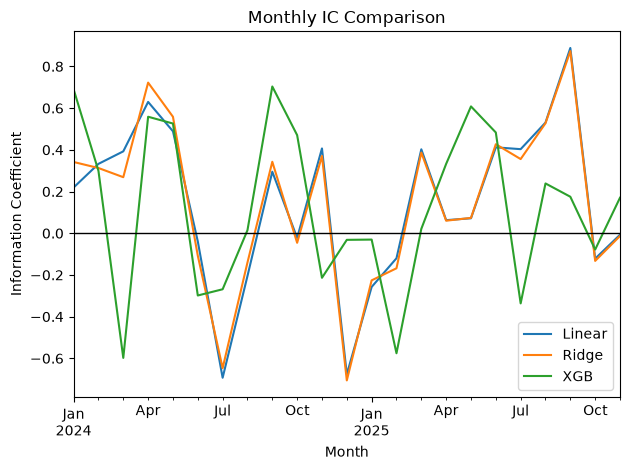

In [41]:
mics.plot()

plt.axhline(0, color="black", linewidth=1)
plt.title("Monthly IC Comparison")
plt.xlabel("Month")
plt.ylabel("Information Coefficient")
plt.legend()
plt.tight_layout()
plt.show();

In [ ]:
#Regime analysis for models
mics.index = pd.to_datetime(mics.index)
market_returns.index = pd.to_datetime(market_returns.index)

regimes = mics.join(
    market_returns.rename("Market_Return"),
    how="inner"
).dropna()

regimes["Regime"] = regimes["Market_Return"].apply(
    lambda r: "Down Market" if r < 0 else "Up Market"
)

print(regimes.head())

              Linear     Ridge       XGB  Market_Return       Regime
Date                                                                
2024-01-31  0.219319  0.341664  0.690156       0.015896    Up Market
2024-02-29  0.332663  0.312755  0.299164       0.051721    Up Market
2024-03-31  0.392694  0.268773 -0.597785       0.031019    Up Market
2024-04-30  0.629716  0.722301  0.558633      -0.041615  Down Market
2024-05-31  0.488796  0.558455  0.526078       0.048021    Up Market


In [43]:
models = ["Linear", "Ridge", "XGB"]

regimes_summary = regimes.groupby("Regime")[models].agg(
    ["mean", "std", "count"]
)

print(regimes_summary.round(3))

            Linear               Ridge                 XGB             
              mean    std count   mean    std count   mean    std count
Regime                                                                 
Down Market  0.046  0.452     6  0.042  0.489     6  0.129  0.419     6
Up Market    0.183  0.375    17  0.187  0.365    17  0.123  0.394    17


XGB has a higher mean than Ridge and Linear for Down Market, and a lower mean for Down Market. XGB has the lowest standard deviation for down markets, but the highest standard deviation for up markets.

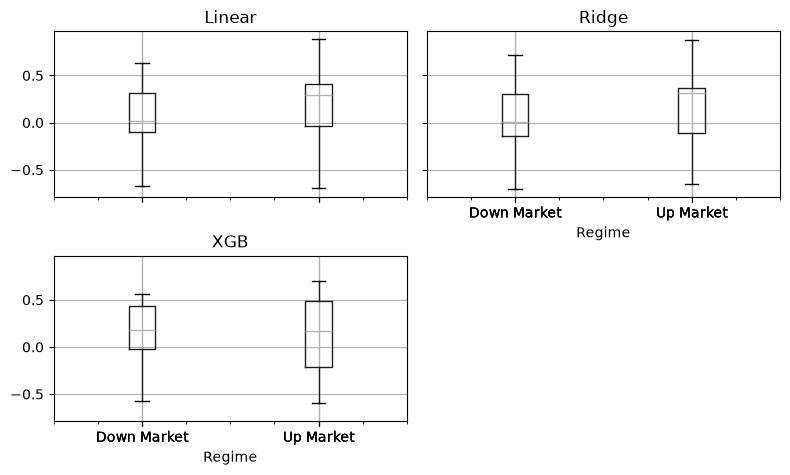

In [47]:
regimes.boxplot(
    column=models,
    by="Regime",
    figsize=(8, 5)
)

plt.suptitle("")
plt.title("Monthly IC by Market Regime")
plt.xlabel("Market Regime")
plt.ylabel("Information Coefficient")
plt.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

In [49]:
for regime, group in regimes.groupby("Regime"):
    print(f"\n{regime}:")
    print("Months:", len(group))
    print("XGB mean IC:", round(group["XGB"].mean(), 3))
    print("Fraction of negative IC months:",
          round((group["XGB"] < 0).mean(), 3))


Down Market:
Months: 6
XGB mean IC: 0.129
Fraction of negative IC months: 0.333

Up Market:
Months: 17
XGB mean IC: 0.123
Fraction of negative IC months: 0.412
